In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split

DATA_PATH =  Path("../data/interim/train.parquet")

### Catboost (Raw Data)

In [9]:
applications = pd.read_parquet(DATA_PATH)

target_col = "TARGET"
id_col = "SK_ID_CURR"



In [10]:
labeled = applications.loc[applications[target_col].notna()].copy()
y = pd.to_numeric(labeled[target_col], errors="raise")

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"{target_col} must contain only 0/1 labels.")

y = y.astype("int8")

print(f"Labeled rows: {len(labeled):,}")
print("Target distribution:")
print(y.value_counts(normalize=True).sort_index().rename("proportion"))



Labeled rows: 246,008
Target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [11]:

# Exclude the target and identifier from the model features.
drop_cols = [col for col in [target_col, id_col] if col in labeled.columns]
X = labeled.drop(columns=drop_cols)

# Split labeled rows into 70% train, 15% validation, and 15% test.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_holdout,
    y_holdout,
    test_size=0.50,
    random_state=42,
    stratify=y_holdout,
)


In [12]:
# Pass categorical columns to CatBoost by name.
cat_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()


def prepare_categorical_values(frame, cat_columns):
    """Replace missing categorical values with a string CatBoost can encode."""
    frame = frame.copy()

    for col in cat_columns:
        frame[col] = (
            frame[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    return frame
X_train = prepare_categorical_values(X_train, cat_features)
X_valid = prepare_categorical_values(X_valid, cat_features)
X_test = prepare_categorical_values(X_test, cat_features)




In [13]:
model = CatBoostClassifier(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    allow_writing_files=False,
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True,
)


0:	test: 0.6524110	best: 0.6524110 (0)	total: 121ms	remaining: 3m 1s
100:	test: 0.7456963	best: 0.7456963 (100)	total: 6.63s	remaining: 1m 31s
200:	test: 0.7519152	best: 0.7519228 (199)	total: 12.9s	remaining: 1m 23s
300:	test: 0.7551930	best: 0.7551999 (299)	total: 19.4s	remaining: 1m 17s
400:	test: 0.7568079	best: 0.7568079 (400)	total: 25.8s	remaining: 1m 10s
500:	test: 0.7577174	best: 0.7577174 (500)	total: 32.6s	remaining: 1m 4s
600:	test: 0.7582709	best: 0.7582981 (598)	total: 39.3s	remaining: 58.8s
700:	test: 0.7588196	best: 0.7588380 (699)	total: 45.9s	remaining: 52.4s
800:	test: 0.7592352	best: 0.7592417 (793)	total: 52.4s	remaining: 45.7s
900:	test: 0.7594804	best: 0.7595245 (885)	total: 59.5s	remaining: 39.5s
1000:	test: 0.7598934	best: 0.7598934 (1000)	total: 1m 6s	remaining: 33.1s
1100:	test: 0.7597975	best: 0.7600345 (1026)	total: 1m 13s	remaining: 26.6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.760034468
bestIteration = 1026

Shrink model to fi

CatBoostClassifier(allow_writing_files=False, depth=6, eval_metric='AUC', iterations=1500, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

Best iteration: 1026
Test ROC AUC: 0.7601
Test Average Precision: 0.2388


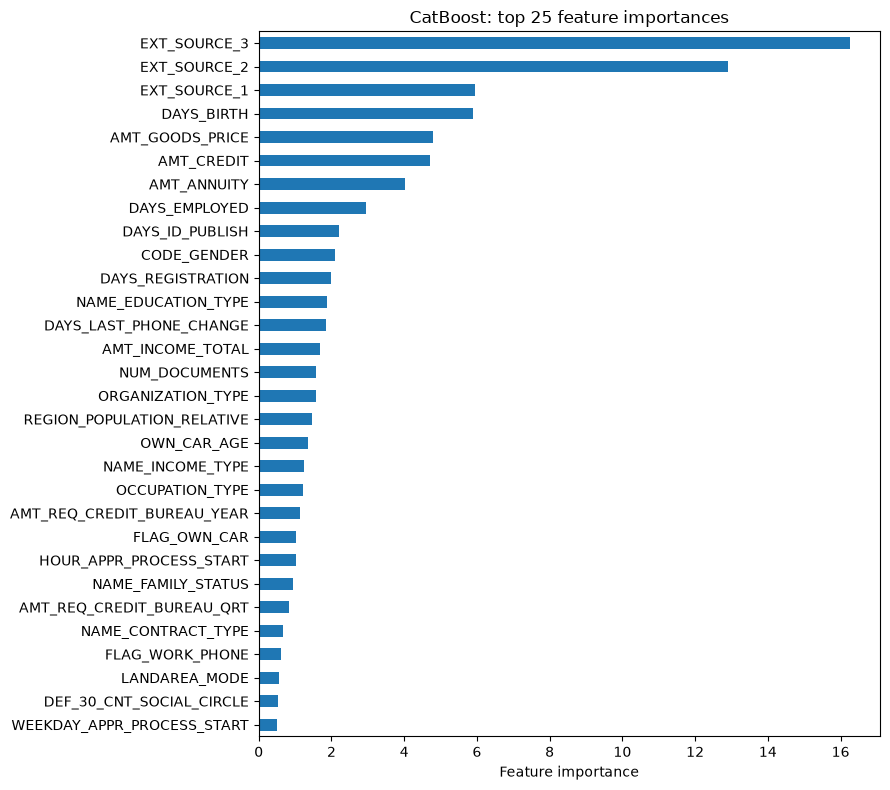

In [15]:
# Evaluate the held-out test set.
test_probabilities = model.predict_proba(X_test)[:, 1]

print(f"Best iteration: {model.get_best_iteration()}")
print(f"Test ROC AUC: {roc_auc_score(y_test, test_probabilities):.4f}")
print(f"Test Average Precision: {average_precision_score(y_test, test_probabilities):.4f}")


# Plot the 25 most important features.
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns,
).nlargest(30).sort_values()

ax = importance.plot(kind="barh", figsize=(9, 8))
ax.set_title("CatBoost: top 25 feature importances")
ax.set_xlabel("Feature importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

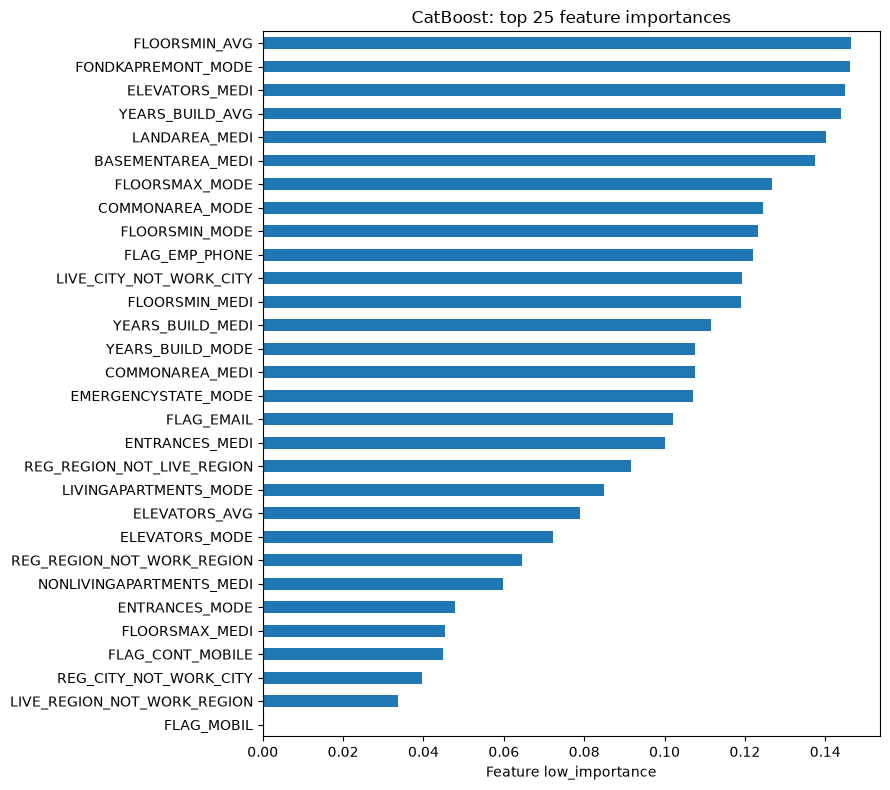

In [16]:

# Plot the 25 most important features.
low_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns,
).nsmallest(30).sort_values()

ax = low_importance.plot(kind="barh", figsize=(9, 8))
ax.set_title("CatBoost: top 25 feature importances")
ax.set_xlabel("Feature low_importance")
ax.set_ylabel("")
plt.tight_layout()
plt.show()